# 02. 작은 예제: support 16개 → query 약물 하나의 ΔRNA

새 세포주에서 약물 16개만 실험했다고 하자. 17번째 약물의 RNA 변화를 어떻게 예측하는지 실제 숫자로 따라간다.

- 여기서 "새 세포주"는 **source 가상 target**(학습에 쓰지 않은 meta-validation 세포주)이다. HCC 자료는 열지 않는다.
- 아무것도 학습하지 않는다. 동결된 모델 하나(seed 42)를 불러와 계산만 한다.
- 서버의 source 단위 저장소가 필요하다(`experiments/episodic_residual_r2/env.sh`를 읽은 환경에서 실행).

용어:
- **Δ**: 같은 plate의 대조군 평균 대비 약물 처리 후 978개 유전자의 변화.
- **f0**: 다른 세포주들에서 같은 약물이 보인 Δ의 평균(이 세포주와 같은 계열은 뺀다).
- **잔차**: 이 세포주의 실제 Δ에서 f0를 뺀 것. support 16개에서만 알 수 있다.

In [1]:
import os, json, sys
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
ROOT = os.environ.get("R2_ROOT", os.path.abspath(os.path.join(os.getcwd(), "..", "..")) if os.path.basename(os.getcwd()) == "episodic_residual_r2" else os.getcwd())
os.chdir(ROOT); sys.path.insert(0, ROOT)
pd.set_option("display.width", 200); pd.set_option("display.float_format", lambda v: f"{v:.4f}")
BLUE, ORANGE, AQUA, YELLOW, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8a8983"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.axisbelow": True,
                     "grid.color": "#e4e3df", "grid.linewidth": 0.6, "axes.edgecolor": "#8a8983", "font.size": 10,
                     "lines.linewidth": 2, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb"})
MAN = "manifests/episodic_residual_r2"
LABEL = {"no_change": "no change", "source_same_drug_mean": "source same-drug mean (f0)", "mean_offset": "f0 + mean offset",
         "shrunk_same_drug_mean": "shrunk f0 (added)", "shrunk_mean_offset": "shrunk f0 + shrunk offset (added)",
         "ecfp_ridge": "ECFP residual ridge", "ecfp_krr": "ECFP Tanimoto KRR", "allfeat_krr": "same-input untrained KRR",
         "generic_cnp": "generic CNP", "residual_adapter": "proposed adapter", "residual_adapter__zero_residual": "proposed, residual set to 0",
         "residual_adapter__shuffle_residual": "proposed, residual rows swapped", "transigen_as_is": "TranSiGen as is",
         "transigen_offset": "TranSiGen + offset", "transigen_full_ft": "TranSiGen full fine-tuning"}
MAIN = ["no_change", "source_same_drug_mean", "mean_offset", "shrunk_same_drug_mean", "shrunk_mean_offset", "ecfp_ridge", "ecfp_krr", "allfeat_krr",
        "generic_cnp", "residual_adapter", "transigen_as_is", "transigen_offset", "transigen_full_ft"]

In [2]:
import torch
from src.episodic_residual_r2.data import Source, Features
from src.episodic_residual_r2 import methods as M
from src.episodic_residual_r2.suite import load_learned
src = Source("cpu")
CELL, SEED, K = "HCC515", 1, 16
ci = list(src.cell_name).index(CELL)
assert src.cell_role[ci] == "val"                       # a held-out source cell line, not a training one
ep = src.eval_episode(ci, SEED)
inp = ep.inputs(K)                                      # everything a method may see: no query label inside
names = src.groups.drug_group.to_numpy()
print("virtual target:", CELL, "| family:", ep.family, "| support K =", K, "| query drugs:", len(ep.g_q))
print("support drugs:", ", ".join(names[ep.g_s[:K]]))

virtual target: HCC515 | family: HCC515 | support K = 16 | query drugs: 472
support drugs: G:BRD-K32112425, G:BRD-K66046182, G:BRD-K16277217, G:BRD-K54771420, G:BRD-K30509186, G:BRD-A61899133, G:BRD-K25164076, G:BRD-K02708799, G:BRD-K39096267, G:BRD-K51966657, G:BRD-A13982089, G:BRD-K06902185, G:BRD-K60936420, G:BRD-K84996949, G:BRD-K18799075, G:BRD-K08502430


## 1. 출발점: 다른 세포주에서 본 같은 약물의 평균(f0)

In [3]:
rmse = lambda p, y: torch.sqrt(((p - y) ** 2).mean(-1))
truth = ep.y_q                                           # used for scoring only
f0 = M.same_drug_mean(inp)
order = torch.argsort(rmse(f0, truth))
q = int(order[len(order) // 2])                          # the query drug with the median f0 error: a typical case
print("example query drug:", names[ep.g_q[q]], "| source cell lines behind its f0:", int(inp["n0_q"][q]))
print(f"no change      : RMSE {rmse(torch.zeros_like(truth[q]), truth[q]):.4f}")
print(f"f0             : RMSE {rmse(f0[q], truth[q]):.4f}   correlation with truth {np.corrcoef(f0[q].numpy(), truth[q].numpy())[0, 1]:.3f}")

example query drug: G:BRD-K28183345 | source cell lines behind its f0: 9
no change      : RMSE 0.4015
f0             : RMSE 0.4240   correlation with truth -0.005


## 2. support 16개가 알려 주는 것: 잔차와 그 평균(offset)

support 약물마다 `실제 Δ − f0`를 계산한다. 16개의 평균이 "이 세포주는 전반적으로 이만큼 다르다"는 공통 offset이다.

In [4]:
e = inp["y_s"] - inp["f0_s"]                           # (16, 978) support residuals
b, R = M.split_residual(inp)                             # b: mean residual, R: residual minus the mean
print("support residual size (RMS per drug):", np.round(torch.sqrt((e ** 2).mean(1)).numpy(), 3))
print(f"common offset size (RMS over genes): {torch.sqrt((b ** 2).mean()):.4f}")
print(f"share of support residual energy carried by the common offset: {float((b ** 2).sum() * K / (e ** 2).sum()):.3f}")
mo = M.mean_offset(inp)
print(f"f0 + offset    : RMSE {rmse(mo[q], truth[q]):.4f}")

support residual size (RMS per drug): [0.313 0.412 0.448 0.361 0.529 0.293 0.486 0.363 0.447 0.534 0.424 0.296
 0.38  0.518 0.427 0.455]
common offset size (RMS over genes): 0.1065
share of support residual energy carried by the common offset: 0.063
f0 + offset    : RMSE 0.4211


## 3. 축소(shrinkage): 적은 표본의 평균은 덜 믿는다

f0는 몇 개 세포주의 평균이고 offset은 16개 약물의 평균이라 둘 다 잡음이 섞여 있다.
source에서 미리 정한 비율로 0 쪽으로 당긴 것이 추가 기준선이다(이 연구에서 계획 뒤에 덧붙인 진단).

In [5]:
sh = json.load(open(f"{MAN}/shrink_selection.json"))["selected"][str(K)]
kf, kb = sh["shrunk_mean_offset"]["kappa_f"], sh["shrunk_mean_offset"]["kappa_b"]
n = float(inp["n0_q"][q])
print(f"f0 weight for this drug  = n/(n+{kf:g}) = {n / (n + kf):.3f}     offset weight = K/(K+{kb:g}) = {K / (K + kb):.3f}")
sf = M.shrunk_prediction(inp, sh["shrunk_same_drug_mean"]["kappa_f"], "inf")
so = M.shrunk_prediction(inp, kf, kb)
print(f"shrunk f0              : RMSE {rmse(sf[q], truth[q]):.4f}")
print(f"shrunk f0 + offset     : RMSE {rmse(so[q], truth[q]):.4f}")

f0 weight for this drug  = n/(n+8) = 0.529     offset weight = K/(K+16) = 0.500
shrunk f0              : RMSE 0.4081
shrunk f0 + offset     : RMSE 0.3968


## 4. 제안법: 닮은 support 약물의 잔차를 빌려 온다

동결된 모델은 약물마다 좌표(embedding)를 만든다. query 약물과 좌표가 가까운 support 약물의 "평균을 뺀 잔차"에 큰 가중치를 주어 더한다.
가중치는 정답을 보지 않고 좌표와 λ만으로 닫힌 식으로 계산된다.

In [6]:
sel = json.load(open(f"{MAN}/model_selection.json"))["final"]["residual_adapter"]["42"]
model = load_learned(sel, src, "cpu")
fmap = Features.load(os.path.join(os.environ["R2_PROC"], "feature_basis.npz"), "cpu")
with torch.no_grad():
    ft = fmap.build(inp, src.FP)
    zs, zq = model.embed(ft, "s"), model.embed(ft, "q")
    m = zs.mean(0, keepdim=True); zs, zq = zs - m, zq - m
    W = (zq @ zs.T).double() @ torch.linalg.inv((zs @ zs.T).double() + model.lam().double() * torch.eye(K, dtype=torch.float64))
    pred = model(inp, ft)
    pred0 = model(inp, ft, zero_residual=True)
w = W[q].numpy()
top = np.argsort(-np.abs(w))[:5]
print(f"lambda = {float(model.lam()):.3f} | variant = {sel['variant']}")
print("five support drugs with the largest weight for", names[ep.g_q[q]])
for i in top:
    print(f"  {names[ep.g_s[i]]:28s} weight {w[i]:+.3f}")
print(f"sum of |weights| = {np.abs(w).sum():.3f}")
print(f"proposed, per-drug part set to 0 : RMSE {rmse(pred0[q], truth[q]):.4f}")
print(f"proposed                         : RMSE {rmse(pred[q], truth[q]):.4f}")

lambda = 0.615 | variant = {'shrink_offset': True, 'shrink_by_k': True}
five support drugs with the largest weight for G:BRD-K28183345
  G:BRD-A61899133              weight +0.087
  G:BRD-K18799075              weight +0.085
  G:BRD-K54771420              weight +0.078
  G:BRD-K51966657              weight -0.048
  G:BRD-K84996949              weight -0.047
sum of |weights| = 0.598
proposed, per-drug part set to 0 : RMSE 0.4191
proposed                         : RMSE 0.4092


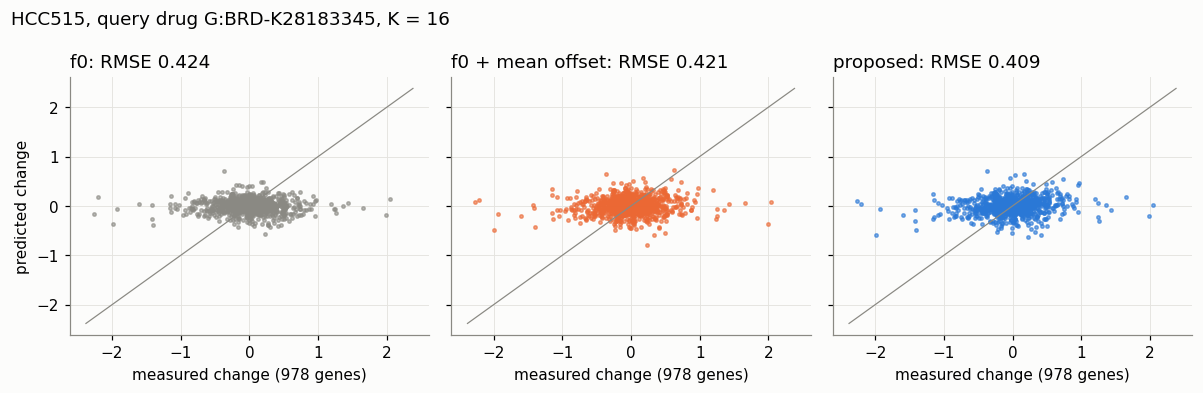

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.6), sharex=True, sharey=True)
for ax, (lab, p, c) in zip(axes, [("f0", f0[q], GREY), ("f0 + mean offset", mo[q], ORANGE), ("proposed", pred[q], BLUE)]):
    ax.scatter(truth[q].numpy(), p.numpy(), s=5, color=c, alpha=0.6)
    lim = float(truth[q].abs().max()) * 1.05
    ax.plot([-lim, lim], [-lim, lim], color="#8a8983", linewidth=0.8)
    ax.set_title(f"{lab}: RMSE {rmse(p, truth[q]):.3f}", loc="left"); ax.set_xlabel("measured change (978 genes)")
axes[0].set_ylabel("predicted change"); plt.suptitle(f"{CELL}, query drug {names[ep.g_q[q]]}, K = {K}", x=0.01, ha="left"); plt.tight_layout(); plt.show()

## 5. 한 약물이 아니라 이 세포주의 모든 query 약물에서

약물 하나의 결과는 우연일 수 있다. 같은 계산을 이 episode의 모든 query 약물에 적용한 평균이다.
9개 계열 전체의 평균은 노트북 01과 `RESULTS.md`에 있다.

In [8]:
with torch.no_grad():
    cnp = load_learned(json.load(open(f"{MAN}/model_selection.json"))["final"]["generic_cnp"]["42"], src, "cpu")
    pc = cnp(inp, ft)
allq = {"no change": torch.zeros_like(truth), "f0": f0, "f0 + mean offset": mo, "shrunk f0": sf, "shrunk f0 + shrunk offset": so,
        "generic CNP (seed 42)": pc, "proposed, residual 0 (seed 42)": pred0, "proposed (seed 42)": pred}
tab = pd.DataFrame({"mean query RMSE": {k: float(rmse(v, truth).mean()) for k, v in allq.items()},
                    "this drug": {k: float(rmse(v[q], truth[q])) for k, v in allq.items()}})
print(f"{CELL}, support seed {SEED}, K = {K}, {len(ep.g_q)} query drugs"); print(tab.to_string())

HCC515, support seed 1, K = 16, 472 query drugs
                                mean query RMSE  this drug
no change                                0.4806     0.4015
f0                                       0.4674     0.4240
f0 + mean offset                         0.4736     0.4211
shrunk f0                                0.4555     0.4081
shrunk f0 + shrunk offset                0.4542     0.3968
generic CNP (seed 42)                    0.4517     0.3857
proposed, residual 0 (seed 42)           0.4691     0.4191
proposed (seed 42)                       0.4674     0.4092


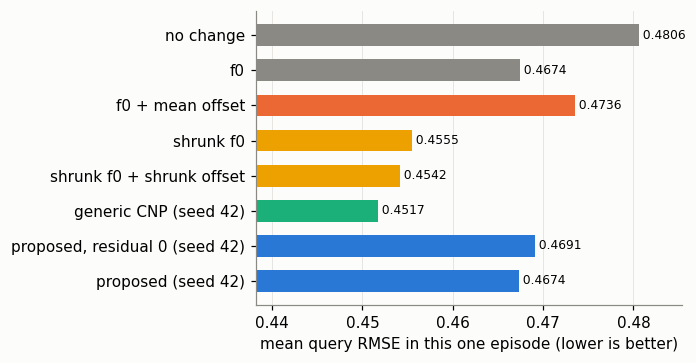

In [9]:
fig, ax = plt.subplots(figsize=(6.4, 3.4))
v = tab["mean query RMSE"]
ax.barh(range(len(v)), v.values, color=[GREY, GREY, ORANGE, YELLOW, YELLOW, AQUA, BLUE, BLUE], height=0.62)
ax.set_yticks(range(len(v))); ax.set_yticklabels(v.index); ax.invert_yaxis()
ax.set_xlim(v.min() * 0.97, v.max() * 1.01); ax.set_xlabel("mean query RMSE in this one episode (lower is better)")
for i, x in enumerate(v.values):
    ax.text(x, i, f" {x:.4f}", va="center", fontsize=8)
ax.grid(axis="y", visible=False); plt.tight_layout(); plt.show()

## 읽는 법

- 이 예제는 세포주 하나, support 추출 한 번의 결과다. 방법 간 순서는 `RESULTS.md`의 9개 계열 평균과 HCC 표로 판단한다.
- "제안법"과 "제안법(약물별 항 0)"의 차이가 약물별 보정이 더한 몫이다. 나머지는 f0와 offset(및 그 축소)에서 온다.